Step 1 : Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Step 2 : Extract Master Ginger Dataset

In [2]:
import os
import zipfile

ZIP_PATH = "/content/drive/MyDrive/10.IIT_FELLOWSHIP/datasets/dataset_ginger_v1.zip"
DATASET_PATH = "/content/Master_Ginger_Dataset"

if not os.path.exists(DATASET_PATH):
    print("Extracting Dataset...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall("/content")
    print("Dataset Extracted Successfully!")
else:
    print("Dataset already exists.")

Extracting Dataset...
Dataset Extracted Successfully!


In [3]:
!pip install imagehash -q

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import imagehash

import tensorflow as tf
from tensorflow.keras import layers, Sequential, Model
from tensorflow.keras.layers import (
    Input, Rescaling, Conv2D, MaxPooling2D, BatchNormalization,
    Dropout, GlobalAveragePooling2D, Dense
)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger
)
from tensorflow.keras.applications import MobileNetV2, ResNet50, EfficientNetB0
from tensorflow.keras.applications import mobilenet_v2, resnet50, efficientnet

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split

print("TensorFlow Version :", tf.__version__)
print("GPUs available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version : 2.21.0
GPUs available: []


Dataset Audit


In [4]:
dataset_path = "/content/Master_Ginger_Dataset"

classes = sorted([
    f for f in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, f))
])

summary = []
total_images = 0
for cls in classes:
    class_path = os.path.join(dataset_path, cls)
    count = len([f for f in os.listdir(class_path) if f.lower().endswith((".jpg", ".jpeg", ".png"))])
    total_images += count
    summary.append([cls, count])

dataset_df = pd.DataFrame(summary, columns=["Disease Class", "Number of Images"])
print(f"Total Images : {total_images}")
dataset_df

Total Images : 15595


,Disease Class,Number of Images
0,Bacterial_Wilt,2663
1,Damage_Pest,2076
2,Dehydrated,3372
3,Healthy,4220
4,Leaf_Blight,3264


In [7]:
import glob

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Create a list of all images with their paths, class names, and labels
# Mapping Healthy to 0, and other categories to 1 (or specific integer class IDs depending on requirements)
image_records = []

for cls in classes:
    class_path = os.path.join(dataset_path, cls)
    # Get all image files in this class directory
    files = glob.glob(os.path.join(class_path, "*"))
    files = [f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))]

    for f in files:
        # Let's map 'Healthy' to label 0, and any other disease category to 1 for binary comparison,
        # or we can keep multiclass labels if needed. Given the binary_label check in the visualization cell:
        # row["label"] == 0 -> "Healthy", else "Diseased"
        label = 0 if cls == "Healthy" else 1

        image_records.append({
            "path": f,
            "class": cls,
            "label": label
        })

df = pd.DataFrame(image_records)
print(f"Created DataFrame with {len(df)} images.")
display(df.head())

Created DataFrame with 15595 images.


,path,class,label
0,/content/Master_Ginger_Dataset/Bacterial_Wilt/...,Bacterial_Wilt,1
1,/content/Master_Ginger_Dataset/Bacterial_Wilt/...,Bacterial_Wilt,1
2,/content/Master_Ginger_Dataset/Bacterial_Wilt/...,Bacterial_Wilt,1
3,/content/Master_Ginger_Dataset/Bacterial_Wilt/...,Bacterial_Wilt,1
4,/content/Master_Ginger_Dataset/Bacterial_Wilt/...,Bacterial_Wilt,1


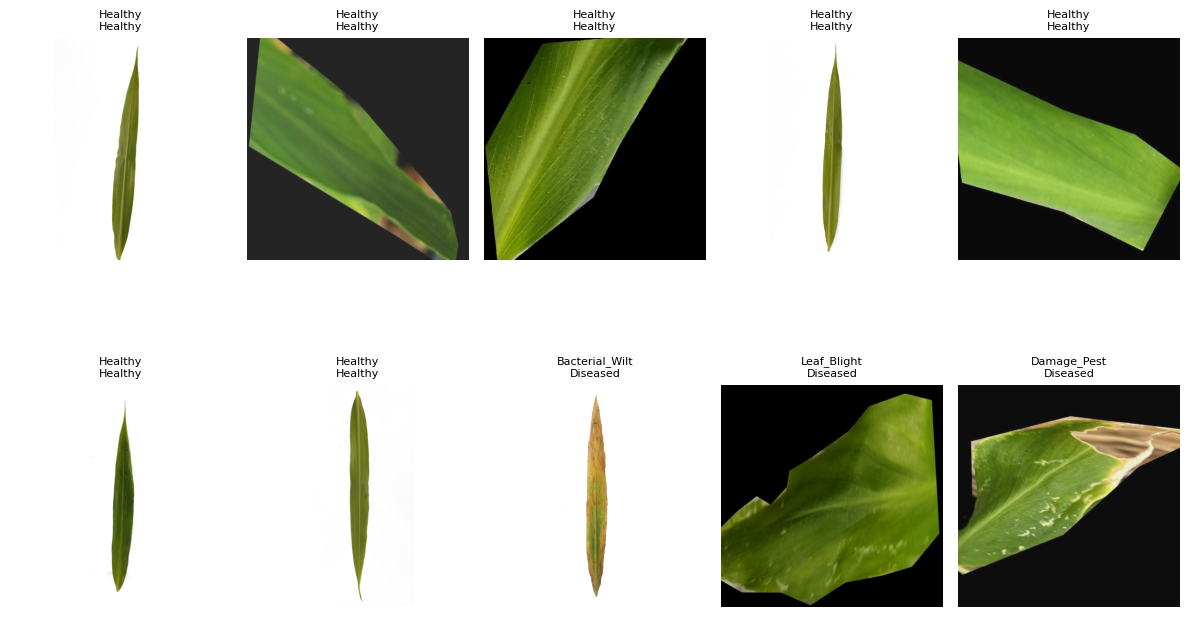

In [8]:
plt.figure(figsize=(12, 8))

sample_df = df.sample(
    min(10, len(df)),
    random_state=SEED
)

for i, (_, row) in enumerate(sample_df.iterrows()):

    img = Image.open(row["path"]).convert("RGB")

    plt.subplot(2, 5, i + 1)
    plt.imshow(img)

    binary_label = (
        "Healthy" if row["label"] == 0
        else "Diseased"
    )

    plt.title(
        f'{row["class"]}\n{binary_label}',
        fontsize=8
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

We divide the image dataset into 70% training, 15% validation and 15% testing sets. Stratified splitting maintains the proportion of healthy and diseased images across all three sets, preventing major class-distribution differences.

In [9]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nTraining distribution:")
print(train_df["label"].value_counts())

print("\nValidation distribution:")
print(val_df["label"].value_counts())

print("\nTesting distribution:")
print(test_df["label"].value_counts())

Training: 10916
Validation: 2339
Testing: 2340

Training distribution:
label
1    7962
0    2954
Name: count, dtype: int64

Validation distribution:
label
1    1706
0     633
Name: count, dtype: int64

Testing distribution:
label
1    1707
0     633
Name: count, dtype: int64


We resize all images to 128 × 128 pixels, convert them into tensors and normalize their RGB channels. Random horizontal flipping and rotation are applied only to training images to improve model generalization.

In [11]:
from torchvision import transforms

IMAGE_SIZE = 128
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

We create a custom Dataset class to load leaf images and their corresponding binary labels. Each image is converted into RGB format and passed through the appropriate preprocessing transformation.

In [14]:
import torch
from torch.utils.data import Dataset, DataLoader

class LeafDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        row = self.data.iloc[index]

        image = Image.open(
            row["path"]
        ).convert("RGB")

        label = torch.tensor(
            row["label"],
            dtype=torch.float32
        )

        if self.transform:
            image = self.transform(image)

        return image, label


train_dataset = LeafDataset(
    train_df, train_transform
)

val_dataset = LeafDataset(
    val_df, test_transform
)

test_dataset = LeafDataset(
    test_df, test_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


We design a shallow Convolutional Neural Network using PyTorch. The network extracts spatial features from leaf images through convolution and max-pooling operations. The extracted feature maps are flattened and passed through fully connected Linear layers to produce a binary classification output.

In [18]:
import torch
import torch.nn as nn

# Configure device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

class ShallowCNN(nn.Module):

    def __init__(self):

        super(ShallowCNN, self).__init__()

        # First convolution block
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=16,
            kernel_size=3,
            padding=1
        )

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # Second convolution block
        self.conv2 = nn.Conv2d(
            in_channels=16,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        self.relu = nn.ReLU()

        # Reduce feature map dimensions
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))

        # Fully connected layers
        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(32 * 4 * 4, 64)

        self.fc2 = nn.Linear(64, 1)

    def forward(self, x):

        x = self.relu(self.conv1(x))
        x = self.pool(x)

        x = self.relu(self.conv2(x))
        x = self.pool(x)

        x = self.adaptive_pool(x)

        x = self.flatten(x)

        x = self.relu(self.fc1(x))

        x = self.fc2(x)

        return x


model = ShallowCNN().to(device)

print(model)

print(
    "\nTotal Parameters:",
    sum(p.numel() for p in model.parameters())
)

Using device: cpu
ShallowCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (adaptive_pool): AdaptiveAvgPool2d(output_size=(4, 4))
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=512, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=1, bias=True)
)

Total Parameters: 37985


We configure Binary Cross Entropy with Logits Loss (BCEWithLogitsLoss) for binary classification and the Adam optimizer for parameter updates. A positive-class weight is calculated from the training data to account for the imbalance between healthy and diseased images.

In [19]:
import torch
import torch.optim as optim

negative_count = (train_df["label"] == 0).sum()
positive_count = (train_df["label"] == 1).sum()

pos_weight = torch.tensor(
    [negative_count / positive_count],
    dtype=torch.float32
).to(device)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Positive Class Weight:", pos_weight.item())
print("Optimizer: Adam")
print("Loss Function: BCEWithLogitsLoss")

Positive Class Weight: 0.37101230025291443
Optimizer: Adam
Loss Function: BCEWithLogitsLoss


We train the CNN using the training dataset over multiple epochs. During each iteration, images pass through the CNN, the loss is calculated, and gradients are computed through backpropagation. The Adam optimizer updates the model parameters. Validation loss and accuracy are recorded after every epoch.

In [20]:
EPOCHS = 8

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []


for epoch in range(EPOCHS):

    # Training phase
    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device).unsqueeze(1)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = (outputs >= 0).float()

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    epoch_train_loss = running_loss / total
    epoch_train_acc = correct / total

    # Validation phase
    model.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device).unsqueeze(1)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = (outputs >= 0).float()

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    epoch_val_loss = val_loss / val_total
    epoch_val_acc = val_correct / val_total

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    train_accuracies.append(epoch_train_acc)
    val_accuracies.append(epoch_val_acc)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} "
        f"Train Acc: {epoch_train_acc*100:.2f}% "
        f"Val Loss: {epoch_val_loss:.4f} "
        f"Val Acc: {epoch_val_acc*100:.2f}%"
    )

Epoch [1/8] Train Loss: 0.3309 Train Acc: 69.88% Val Loss: 0.2846 Val Acc: 69.90%
Epoch [2/8] Train Loss: 0.2721 Train Acc: 74.16% Val Loss: 0.2547 Val Acc: 78.50%
Epoch [3/8] Train Loss: 0.2503 Train Acc: 77.30% Val Loss: 0.2436 Val Acc: 78.88%
Epoch [4/8] Train Loss: 0.2385 Train Acc: 78.59% Val Loss: 0.2272 Val Acc: 80.85%
Epoch [5/8] Train Loss: 0.2255 Train Acc: 80.13% Val Loss: 0.2090 Val Acc: 83.28%
Epoch [6/8] Train Loss: 0.2157 Train Acc: 81.14% Val Loss: 0.2035 Val Acc: 82.90%
Epoch [7/8] Train Loss: 0.2070 Train Acc: 81.98% Val Loss: 0.1925 Val Acc: 84.01%
Epoch [8/8] Train Loss: 0.1961 Train Acc: 83.11% Val Loss: 0.1838 Val Acc: 84.82%


We visualize training and validation loss and accuracy across epochs. These graphs help identify convergence, underfitting and potential overfitting during CNN training.

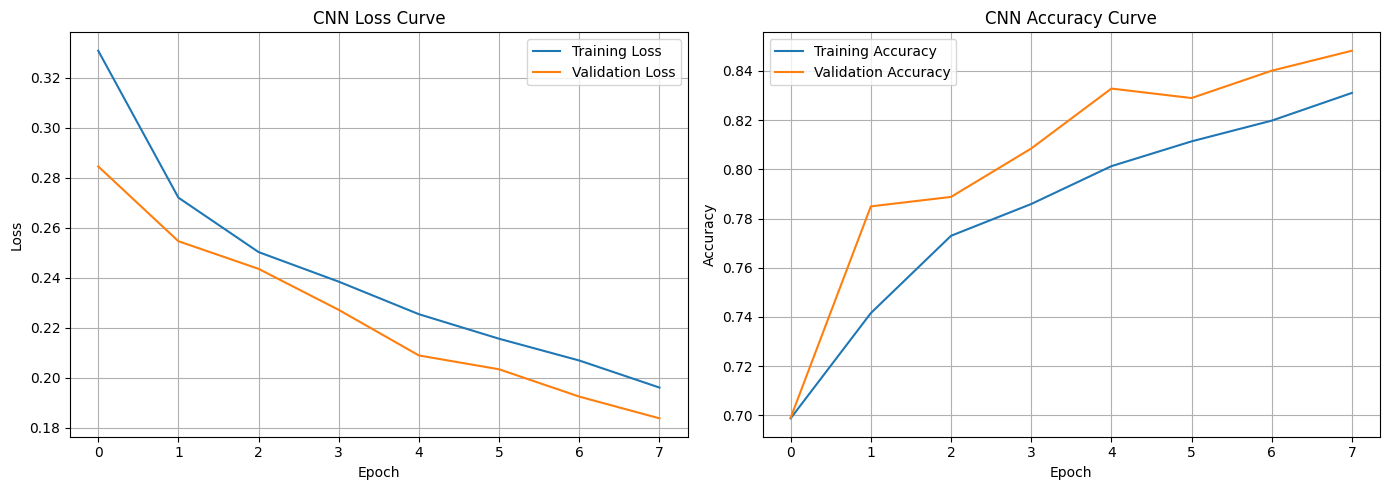

In [21]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Loss Curve")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy Curve")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

We evaluate the trained CNN on the independent testing dataset. Predictions are converted into healthy or diseased labels using a 0.5 probability threshold. Accuracy, precision, recall and F1-score are calculated to assess the classification performance.

In [25]:
from sklearn.metrics import accuracy_score

model.eval()

y_true = []
y_pred = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        probabilities = torch.sigmoid(outputs)

        predictions = (
            probabilities >= 0.5
        ).int().cpu().numpy().flatten()

        y_pred.extend(predictions)

        y_true.extend(labels.numpy().astype(int))


print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Healthy", "Diseased"],
        zero_division=0
    )
)

print(
    "Test Accuracy:",
    accuracy_score(y_true, y_pred) * 100,
    "%"
)

              precision    recall  f1-score   support

     Healthy       0.70      0.83      0.76       633
    Diseased       0.93      0.87      0.90      1707

    accuracy                           0.86      2340
   macro avg       0.82      0.85      0.83      2340
weighted avg       0.87      0.86      0.86      2340

Test Accuracy: 85.8119658119658 %


We generate a confusion matrix to examine correct and incorrect predictions for healthy and diseased leaf images. This helps identify false positives and false negatives in the classification model.

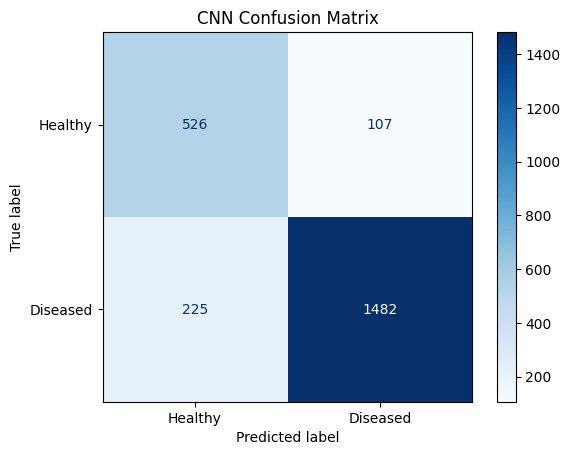

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Healthy", "Diseased"]
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("CNN Confusion Matrix")
plt.show()

We test the trained CNN on an individual leaf image that was not part of the training process. The model generates a probability score and classifies the image as healthy or diseased.

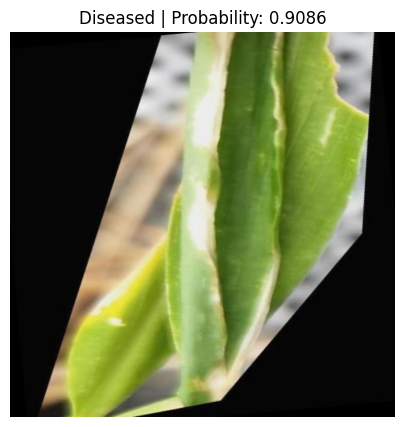

Prediction: Diseased
Disease Probability: 0.9086450934410095


In [27]:
def predict_leaf(image_path):

    model.eval()

    image = Image.open(
        image_path
    ).convert("RGB")

    input_tensor = test_transform(image)
    input_tensor = input_tensor.unsqueeze(0).to(device)

    with torch.no_grad():

        output = model(input_tensor)

        probability = torch.sigmoid(output).item()

    prediction = (
        "Diseased" if probability >= 0.5
        else "Healthy"
    )

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.title(
        f"{prediction} | Probability: {probability:.4f}"
    )
    plt.axis("off")
    plt.show()

    print("Prediction:", prediction)
    print("Disease Probability:", probability)


# Replace with the path to an image
sample_image = test_df.iloc[0]["path"]

predict_leaf(sample_image)

In [28]:
MODEL_PATH = "/content/shallow_cnn_leaf_disease.pth"

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "image_size": IMAGE_SIZE,
        "class_mapping": {
            "Healthy": 0,
            "Diseased": 1
        }
    },
    MODEL_PATH
)

print("Model saved successfully!")
print("Location:", MODEL_PATH)

Model saved successfully!
Location: /content/shallow_cnn_leaf_disease.pth
